I used ChatGPT to assist with debugging. All final code, interpretations, and conclusions are my own work after verification.

Installing packages:

In [76]:
!pip install ucimlrepo pandas numpy seaborn

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try 'pacman -S
    python-xyz', where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Arch-packaged Python package,
    create a virtual environment using 'python -m venv path/to/venv'.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip.
    
    If you wish to install a non-Arch packaged Python application,
    it may be easiest to use 'pipx install xyz', which will manage a
    virtual environment for you. Make sure you have python-pipx
    installed via pacman.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.



Dataset: https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data

Paper: https://royalsocietypublishing.org/rspa/article/471/2182/20150257/57659/Assessing-Beijing-s-PM2-5-pollution-severity

The page provides code to use the dataset in Python. `X` and `y` are casted to pandas `DataFrame`s.

# Task 1: Dataset loading and Initial Exploration

## 1.1: Data loading

In [77]:
from ucimlrepo import fetch_ucirepo 
# import polars as pl
import pandas as pd
import json
  
# fetch dataset 
beijing_pm2_5 = fetch_ucirepo(id=381) 
  
# data (as pandas dataframes) 
X = pd.DataFrame(beijing_pm2_5.data.features)
y = pd.DataFrame(beijing_pm2_5.data.targets )
  
# metadata, in json format. Pretty-print with json.dumps:
print(json.dumps(beijing_pm2_5.metadata, indent = 4)) 
  
# variable information 
print(beijing_pm2_5.variables) 


{
    "uci_id": 381,
    "name": "Beijing PM2.5",
    "repository_url": "https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data",
    "data_url": "https://archive.ics.uci.edu/static/public/381/data.csv",
    "abstract": "This hourly data set contains the PM2.5 data of US Embassy in Beijing. Meanwhile, meteorological data from Beijing Capital International Airport are also included. ",
    "area": "Climate and Environment",
    "tasks": [
        "Regression"
    ],
    "characteristics": [
        "Multivariate",
        "Time-Series"
    ],
    "num_instances": 43824,
    "num_features": 11,
    "feature_types": [
        "Integer",
        "Real"
    ],
    "demographics": [],
    "target_col": [
        "pm2.5"
    ],
    "index_col": [
        "No"
    ],
    "has_missing_values": "yes",
    "missing_values_symbol": "NaN",
    "year_of_dataset_creation": 2015,
    "last_updated": "Sat Mar 16 2024",
    "dataset_doi": "10.24432/C5JS49",
    "creators": [
        "Song Chen"
    

## 1.2: Data shape

In [78]:
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

Shape of X: (43824, 11)
Shape of y: (43824, 1)


## 1.3: First 5 rows

In [79]:
X.head(5)

,year,month,day,hour,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,2010,1,1,0,-21,-11.0,1021.0,NW,1.79,0,0
1,2010,1,1,1,-21,-12.0,1020.0,NW,4.92,0,0
2,2010,1,1,2,-21,-11.0,1019.0,NW,6.71,0,0
3,2010,1,1,3,-21,-14.0,1019.0,NW,9.84,0,0
4,2010,1,1,4,-20,-12.0,1018.0,NW,12.97,0,0


In [80]:
y.head(5)

,pm2.5
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN


## 1.4: Data types of all columns

In [81]:
X.dtypes

year       int64
month      int64
day        int64
hour       int64
DEWP       int64
TEMP     float64
PRES     float64
cbwd         str
Iws      float64
Is         int64
Ir         int64
dtype: object

In [82]:
y.dtypes

pm2.5    float64
dtype: object

## 1.5: Basic statistical summary

The `info()` function prints a concise summary information of a DataFrame and its columns, and the `describe()` function prints a descriptive statistics of all columns in it

In [83]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   year    43824 non-null  int64  
 1   month   43824 non-null  int64  
 2   day     43824 non-null  int64  
 3   hour    43824 non-null  int64  
 4   DEWP    43824 non-null  int64  
 5   TEMP    43824 non-null  float64
 6   PRES    43824 non-null  float64
 7   cbwd    43824 non-null  str    
 8   Iws     43824 non-null  float64
 9   Is      43824 non-null  int64  
 10  Ir      43824 non-null  int64  
dtypes: float64(3), int64(7), str(1)
memory usage: 3.8 MB


In [84]:
X.describe()

,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir
count,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000
mean,2012.000000,6.523549,15.727820,11.500000,1.817246,12.448521,1016.447654,23.889140,0.052734,0.194916
std,1.413842,3.448572,8.799425,6.922266,14.433440,12.198613,10.268698,50.010635,0.760375,1.415867
min,2010.000000,1.000000,1.000000,0.000000,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000
25%,2011.000000,4.000000,8.000000,5.750000,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000
50%,2012.000000,7.000000,16.000000,11.500000,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000
75%,2013.000000,10.000000,23.000000,17.250000,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000
max,2014.000000,12.000000,31.000000,23.000000,28.000000,42.000000,1046.000000,585.600000,27.000000,36.000000


In [85]:
y.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   pm2.5   41757 non-null  float64
dtypes: float64(1)
memory usage: 342.5 KB


In [86]:
y.describe()

,pm2.5
count,41757.000000
mean,98.613215
std,92.050387
min,0.000000
25%,29.000000
50%,72.000000
75%,137.000000
max,994.000000


## 1.6: Initial missing values check

We count the number values in `X` and `y` using the `isna().sum()` function, which counts the numbers of NaN/Null values.

In [87]:
print(f"Number of null values in X: {X.isna().sum()}")
print(f"Number of null values in y: {y.isna().sum()}")

Number of null values in X: year     0
month    0
day      0
hour     0
DEWP     0
TEMP     0
PRES     0
cbwd     0
Iws      0
Is       0
Ir       0
dtype: int64
Number of null values in y: pm2.5    2067
dtype: int64


# 2: Data Quality Assessment

## 2.1: Missing values table with percentages

Percentage of `Null` / `NaN` values in `X`, per column

In [88]:
# Source - https://stackoverflow.com/a/51071085
# Posted by Scott Boston, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-02, License - CC BY-SA 4.0

X.isnull().mean() * 100


year     0.0
month    0.0
day      0.0
hour     0.0
DEWP     0.0
TEMP     0.0
PRES     0.0
cbwd     0.0
Iws      0.0
Is       0.0
Ir       0.0
dtype: float64

Percentage of `Null` / `NaN` values in `y`

In [89]:
# Source - https://stackoverflow.com/a/51071085
# Posted by Scott Boston, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-02, License - CC BY-SA 4.0

y.isnull().mean() * 100


pm2.5    4.716594
dtype: float64

In [90]:
y.isnull().sum()

pm2.5    2067
dtype: int64

## 2.2: Missing values heatmap

We use the `seaborn` library, which has the ability to visualize heatmaps.

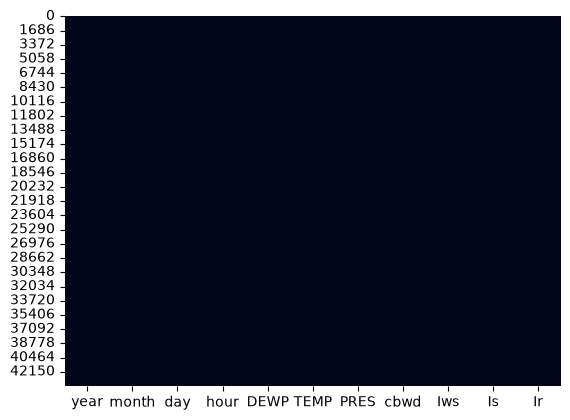

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(X.isna(), cbar=False)
plt.show()

The graph is a solid color as `X` has no missing values.

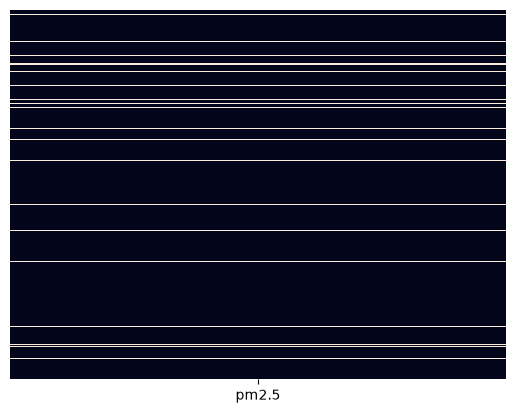

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(y.isna(), cbar=False, yticklabels=False,)
plt.show()

Since `y` only has a singular column, the strips in the middle represent the missing values.

## 2.3: Duplicates count and examples (if any)

We can count duplicates using the `duplicated` function. The parameter `keep = False` will mark all duplicate instances.

In [93]:
X.duplicated(keep = False)

0        False
1        False
2        False
3        False
4        False
         ...  
43819    False
43820    False
43821    False
43822    False
43823    False
Length: 43824, dtype: bool

In [94]:
y.duplicated(keep = False)

0        True
1        True
2        True
3        True
4        True
         ... 
43819    True
43820    True
43821    True
43822    True
43823    True
Length: 43824, dtype: bool

And we can combine the `sum` function to get the total number of duplicates. 

In [95]:
X.duplicated(keep = False).sum()

np.int64(0)

In [96]:
y.duplicated(keep = False).sum()

np.int64(43754)

## 2.4: Box plot for all numerical features

First, we'll look through the list of numerical features

In [97]:
print("Info of X:")
X.info()
print("---")
print("Info of y:")
y.info()

Info of X:
<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   year    43824 non-null  int64  
 1   month   43824 non-null  int64  
 2   day     43824 non-null  int64  
 3   hour    43824 non-null  int64  
 4   DEWP    43824 non-null  int64  
 5   TEMP    43824 non-null  float64
 6   PRES    43824 non-null  float64
 7   cbwd    43824 non-null  str    
 8   Iws     43824 non-null  float64
 9   Is      43824 non-null  int64  
 10  Ir      43824 non-null  int64  
dtypes: float64(3), int64(7), str(1)
memory usage: 3.8 MB
---
Info of y:
<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   pm2.5   41757 non-null  float64
dtypes: float64(1)
memory usage: 342.5 KB


We note that for `y`, there are many missing values. Since the target variable is the amount of PM2.5 (in ug / m^3) measured, we will assume that a missing value means no PM2.5 was measured, and therefore the amount is 0 ug / m^3:

In [98]:
y = y.fillna(0)
y

,pm2.5
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
43819,8.0
43820,10.0
43821,10.0
43822,8.0


There are many numerical columns, so therefore we will not have an individual cell to plot each. Instead, we iterate over them:

In [99]:
for (col, series) in X.items():
    print(col)

year
month
day
hour
DEWP
TEMP
PRES
cbwd
Iws
Is
Ir


Of all the features, only `cbwd` is non-numerical.

In [100]:
predictors = ["year", "month", "day", "hour", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
X[predictors]

,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir
0,2010,1,1,0,-21,-11.0,1021.0,1.79,0,0
1,2010,1,1,1,-21,-12.0,1020.0,4.92,0,0
2,2010,1,1,2,-21,-11.0,1019.0,6.71,0,0
3,2010,1,1,3,-21,-14.0,1019.0,9.84,0,0
4,2010,1,1,4,-20,-12.0,1018.0,12.97,0,0
...,...,...,...,...,...,...,...,...,...,...
43819,2014,12,31,19,-23,-2.0,1034.0,231.97,0,0
43820,2014,12,31,20,-22,-3.0,1034.0,237.78,0,0
43821,2014,12,31,21,-22,-3.0,1034.0,242.70,0,0
43822,2014,12,31,22,-22,-4.0,1034.0,246.72,0,0


Thus we can construct the initial boxplot:

<Axes: >

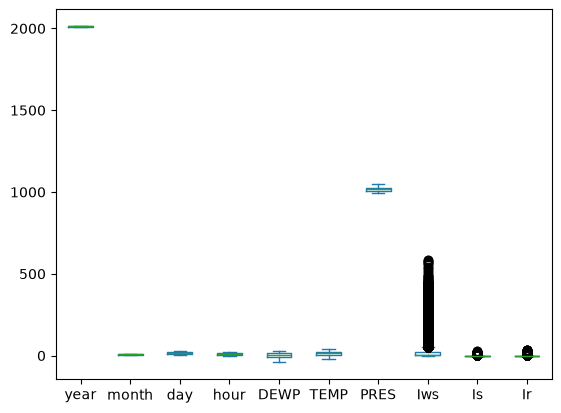

In [101]:
X[predictors].plot.box()

We can see large gaps, so it's better to construct individual box plots:

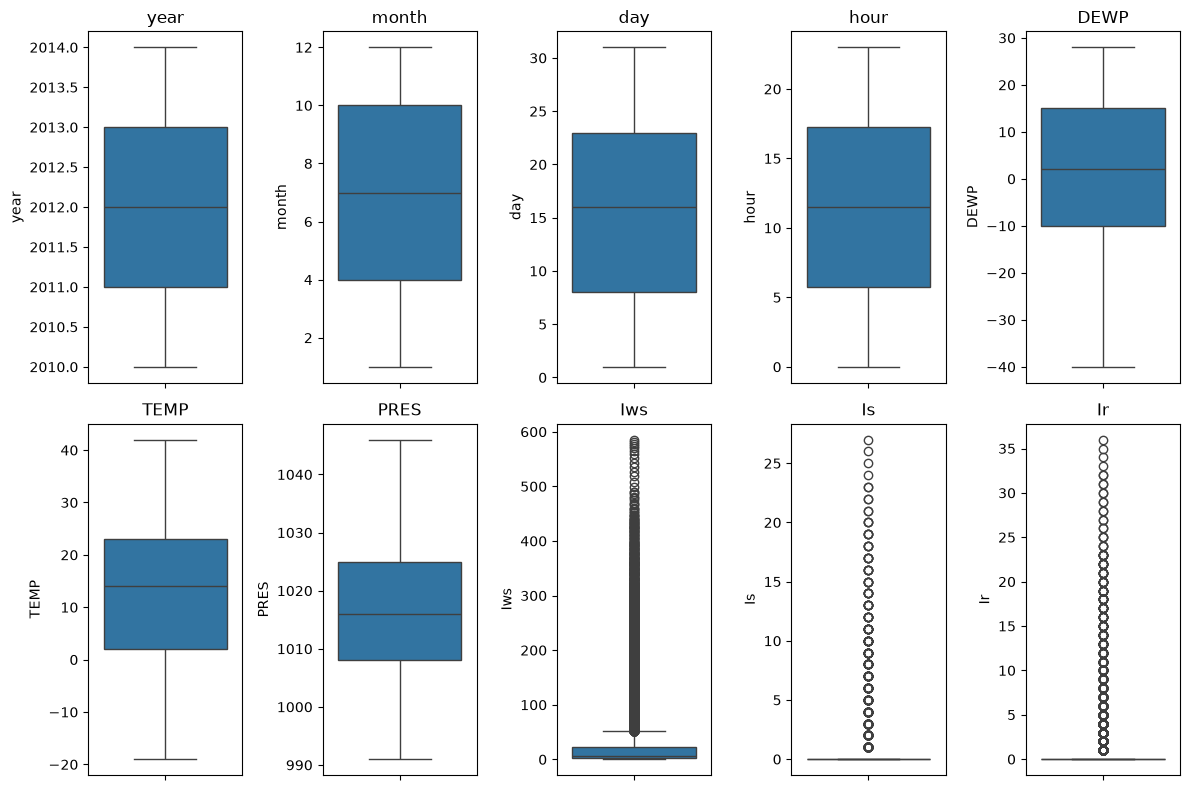

In [102]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 5, figsize=(12, 8))

for predictor, ax in zip(predictors, axes.flat):
    sns.boxplot(y=X[predictor], ax=ax)
    # X[predictor].plot.box(ax=ax)
    ax.set_title(predictor)

plt.tight_layout()
plt.show()

## 2.5: Initial observations about data quality

Overall, the data is of moderately high quality, without too many duplicates, missing values, etc.

# 3: Target Variable Preparation

## 3.1: Target variable info (name and data type)

In [103]:
y


,pm2.5
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
43819,8.0
43820,10.0
43821,10.0
43822,8.0


In [104]:
y.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   pm2.5   43824 non-null  float64
dtypes: float64(1)
memory usage: 342.5 KB


The target variable name is `pm2.5`, and the data type is `float64`. The task is regression.

## 3.2: Target Variable Summary Statistics and Binning

We use the `describe()` function to obtain some summary statistics:

In [105]:
y.describe()

,pm2.5
count,43824.000000
mean,93.962030
std,92.253236
min,0.000000
25%,24.000000
50%,68.000000
75%,132.000000
max,994.000000


The target variable is the level of PM2.5, measured in ug/m^3. In the [paper](https://royalsocietypublishing.org/rspa/article/471/2182/20150257/57659/Assessing-Beijing-s-PM2-5-pollution-severity), the authors define the PM level to be:

- low when it's less than 35 ug/m^3
- polluting when it is between 35 and 150 ug/m^3
- very high when it is more than 150 ug/m^3

We will split the PM2.5 levels into bins following this convention.

As the target value is a float, the task is regression.


In [106]:
def pm25_level(f: float) -> str:
    if f < 35: return "low"
    elif 35 <= f <= 150: return "polluting"
    else: return "very high"

y["level"] = y["pm2.5"].map(pm25_level)
y

,pm2.5,level
0,0.0,low
1,0.0,low
2,0.0,low
3,0.0,low
4,0.0,low
...,...,...
43819,8.0,low
43820,10.0,low
43821,10.0,low
43822,8.0,low


Class distribution

In [107]:
y["level"].value_counts()

level
polluting    20896
low          13937
very high     8991
Name: count, dtype: int64

We can plot the value count:

<Axes: xlabel='level', ylabel='count'>

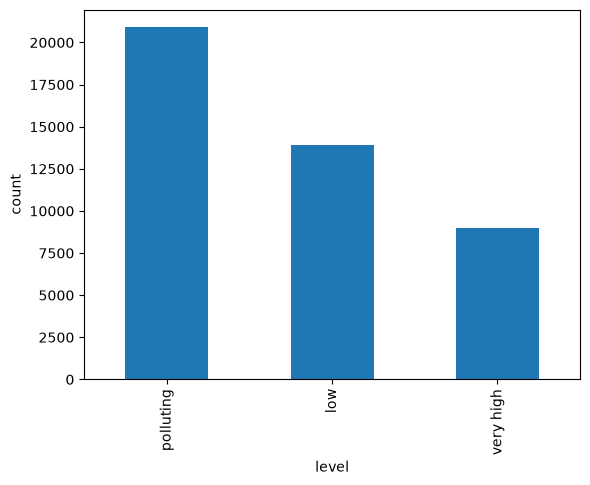

In [108]:
y["level"].value_counts().plot(kind="bar", xlabel="level", ylabel="count")

We can also plot the distribution

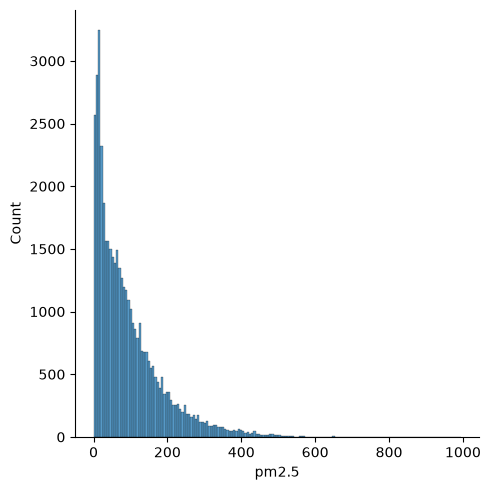

In [109]:
sns.displot(y, x = "pm2.5")

## 3.3: Initial Observations of the Target

Initial observations:

There appears to be an unbalance of the number of values in the levels, which we can assume that it is due to the large range of values in the "polluting" interval, as well as "low" having a small range and "very high" having very limited values.

# Task 4: Univariate Analysis

## 4.1: List of all numerical predictors:

First, we review the types:

In [110]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   year    43824 non-null  int64  
 1   month   43824 non-null  int64  
 2   day     43824 non-null  int64  
 3   hour    43824 non-null  int64  
 4   DEWP    43824 non-null  int64  
 5   TEMP    43824 non-null  float64
 6   PRES    43824 non-null  float64
 7   cbwd    43824 non-null  str    
 8   Iws     43824 non-null  float64
 9   Is      43824 non-null  int64  
 10  Ir      43824 non-null  int64  
dtypes: float64(3), int64(7), str(1)
memory usage: 3.8 MB


We note that while `year`, `month`, `day` and `hour` are technically numerical predictors (that is, they can help in predict values); they are only used to provide relevant time-series information. Therefore, they are not _strictly_ numerical predictors compared to the other numerical predictors. We also note that `cbwd` is a string and therefore not a numerical predictor.

Therefore the numerical predictors are `DWEP`, `TEMP`, `PRES`, `Iws`, `Is`, `Ir`.

In [111]:
predictors = ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
X[predictors]

,DEWP,TEMP,PRES,Iws,Is,Ir
0,-21,-11.0,1021.0,1.79,0,0
1,-21,-12.0,1020.0,4.92,0,0
2,-21,-11.0,1019.0,6.71,0,0
3,-21,-14.0,1019.0,9.84,0,0
4,-20,-12.0,1018.0,12.97,0,0
...,...,...,...,...,...,...
43819,-23,-2.0,1034.0,231.97,0,0
43820,-22,-3.0,1034.0,237.78,0,0
43821,-22,-3.0,1034.0,242.70,0,0
43822,-22,-4.0,1034.0,246.72,0,0


## 4.2: Summary Statistics of all predictors

Similar to above, we can use the `describe()` function to provide summary statistics for all predictors:

In [112]:
X[predictors].describe()

,DEWP,TEMP,PRES,Iws,Is,Ir
count,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000
mean,1.817246,12.448521,1016.447654,23.889140,0.052734,0.194916
std,14.433440,12.198613,10.268698,50.010635,0.760375,1.415867
min,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000
25%,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000
50%,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000
75%,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000
max,28.000000,42.000000,1046.000000,585.600000,27.000000,36.000000


## 4.3: Distribution plots for all predictors

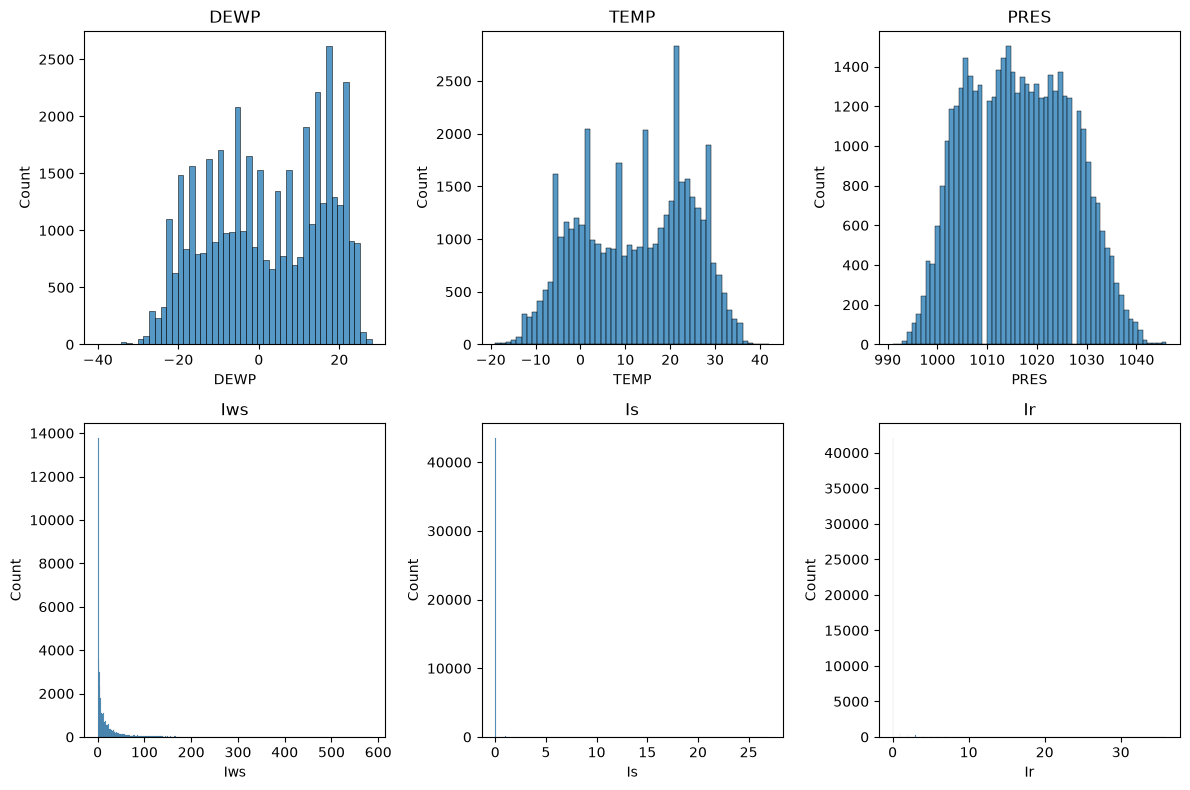

In [113]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for predictor, ax in zip(predictors, axes.flat):
    sns.histplot(x=X[predictor], ax=ax)
    # X[predictor].plot.box(ax=ax)
    ax.set_title(predictor)

plt.tight_layout()
plt.show()

## 4.4: Observations about  distributions

From the graphs, we can see that: 

- `DEWP` is bimodally distributed
- `TEMP` is bimodally distributed
- `PRES` is normally distributed
- `lws`, `ls` and `lr` are left-skewed.

# 5: Multivariate Analysis

## 5.1: Correlation heatmap

First, we construct the _correlation matrix_, by the `.corr()` function. The `numeric_only` parameter restricts this calculation to only numeric columns.

In [114]:
corr_matrix = X.corr(numeric_only=True)
corr_matrix

,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir
year,1.000000e+00,3.070661e-13,3.200526e-15,-3.318729e-15,0.001122,0.045529,-0.012570,-0.064244,-0.017002,-0.024383
month,3.070661e-13,1.000000e+00,1.079604e-02,-1.525086e-16,0.233975,0.170093,-0.062185,0.003043,-0.061672,0.036737
day,3.200526e-15,1.079604e-02,1.000000e+00,-5.312012e-17,0.028559,0.014791,-0.007070,-0.008954,-0.036826,0.002681
hour,-3.318729e-15,-1.525086e-16,-5.312012e-17,1.000000e+00,-0.020988,0.150066,-0.041928,0.056618,-0.002374,-0.006286
DEWP,1.121574e-03,2.339746e-01,2.855899e-02,-2.098769e-02,1.000000,0.824633,-0.778346,-0.296399,-0.034410,0.125090
TEMP,4.552854e-02,1.700926e-01,1.479104e-02,1.500656e-01,0.824633,1.000000,-0.826690,-0.154623,-0.092601,0.049121
PRES,-1.257001e-02,-6.218507e-02,-7.070048e-03,-4.192788e-02,-0.778346,-0.826690,1.000000,0.185355,0.069028,-0.079843
Iws,-6.424368e-02,3.043299e-03,-8.953566e-03,5.661776e-02,-0.296399,-0.154623,0.185355,1.000000,0.021883,-0.010122
Is,-1.700207e-02,-6.167206e-02,-3.682638e-02,-2.373592e-03,-0.034410,-0.092601,0.069028,0.021883,1.000000,-0.009548
Ir,-2.438290e-02,3.673715e-02,2.681328e-03,-6.286241e-03,0.125090,0.049121,-0.079843,-0.010122,-0.009548,1.000000


<Axes: >

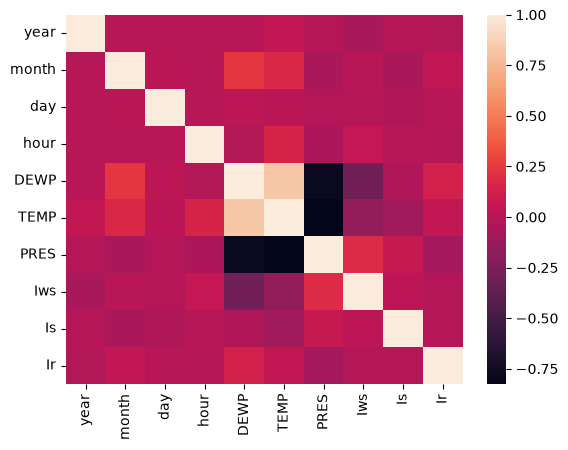

In [115]:
sns.heatmap(corr_matrix)

We can similarly construct a correlation heatmap of the numerical predictors as indicated in section 4:

<Axes: >

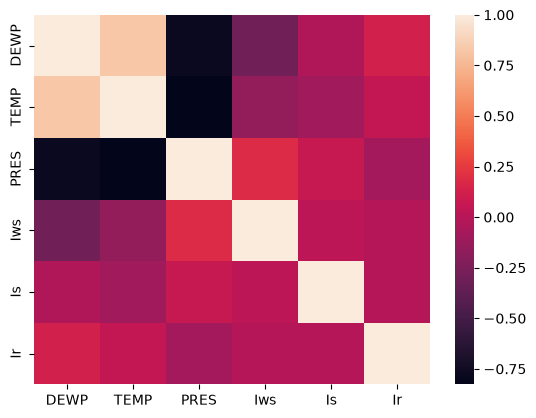

In [116]:
corr_matrix_predictors = X[predictors].corr(numeric_only = True)
sns.heatmap(corr_matrix_predictors)

## 5.2: Top 3 features correlated with the target

We measure the Pearson correlation between each feature and the target. To calculate this, we use the `pearsonr` method from the `scipy` library.

In [117]:
from scipy import stats

numerical_columns = X.corr(numeric_only=True).columns
for (col, series) in X[numerical_columns].items():
    print(col, stats.pearsonr(series, y["pm2.5"]))

year PearsonRResult(statistic=np.float64(0.0168318164948141), pvalue=np.float64(0.00042548182017418504))
month PearsonRResult(statistic=np.float64(-0.0258121128912448), pvalue=np.float64(6.506158781363579e-08))
day PearsonRResult(statistic=np.float64(0.0736889061555061), pvalue=np.float64(7.936588199274396e-54))
hour PearsonRResult(statistic=np.float64(-0.02164583587550566), pvalue=np.float64(5.848861917019284e-06))
DEWP PearsonRResult(statistic=np.float64(0.1582478429765198), pvalue=np.float64(1.1165416712821886e-243))
TEMP PearsonRResult(statistic=np.float64(-0.08983001965737535), pvalue=np.float64(3.370157932332344e-79))
PRES PearsonRResult(statistic=np.float64(-0.045565306191287305), pvalue=np.float64(1.3821294073989633e-21))
Iws PearsonRResult(statistic=np.float64(-0.2341822060158355), pvalue=np.float64(0.0))
Is PearsonRResult(statistic=np.float64(0.022258803760341925), pvalue=np.float64(3.159897553186623e-06))
Ir PearsonRResult(statistic=np.float64(-0.04895378994570203), pvalue=n

Which we can format nicely into a dataset:

In [118]:
results = []
for col, series in X[numerical_columns].items():
    result = stats.pearsonr(series, y["pm2.5"])

    results.append({
        "predictor": col,
        "correlation": abs(result.statistic),
        # "p_value": result.pvalue,
    })
correlations = pd.DataFrame(results)
correlations


,predictor,correlation
0,year,0.016832
1,month,0.025812
2,day,0.073689
3,hour,0.021646
4,DEWP,0.158248
5,TEMP,0.089830
6,PRES,0.045565
7,Iws,0.234182
8,Is,0.022259
9,Ir,0.048954


From which we can see that all numerical features have very weak linear correlations to the target variable.

The top 3 features correlated with the target variable are:

In [119]:
correlations.sort_values("correlation", ascending=False, ).head(3)

,predictor,correlation
7,Iws,0.234182
4,DEWP,0.158248
5,TEMP,0.089830


## 5.3: Identification of multi-colinearity (high correlation between predictors)

We refer to the correlation matrix above:

In [120]:
corr_matrix = X.corr(numeric_only=True).abs()
corr_matrix

,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir
year,1.000000e+00,3.070661e-13,3.200526e-15,3.318729e-15,0.001122,0.045529,0.012570,0.064244,0.017002,0.024383
month,3.070661e-13,1.000000e+00,1.079604e-02,1.525086e-16,0.233975,0.170093,0.062185,0.003043,0.061672,0.036737
day,3.200526e-15,1.079604e-02,1.000000e+00,5.312012e-17,0.028559,0.014791,0.007070,0.008954,0.036826,0.002681
hour,3.318729e-15,1.525086e-16,5.312012e-17,1.000000e+00,0.020988,0.150066,0.041928,0.056618,0.002374,0.006286
DEWP,1.121574e-03,2.339746e-01,2.855899e-02,2.098769e-02,1.000000,0.824633,0.778346,0.296399,0.034410,0.125090
TEMP,4.552854e-02,1.700926e-01,1.479104e-02,1.500656e-01,0.824633,1.000000,0.826690,0.154623,0.092601,0.049121
PRES,1.257001e-02,6.218507e-02,7.070048e-03,4.192788e-02,0.778346,0.826690,1.000000,0.185355,0.069028,0.079843
Iws,6.424368e-02,3.043299e-03,8.953566e-03,5.661776e-02,0.296399,0.154623,0.185355,1.000000,0.021883,0.010122
Is,1.700207e-02,6.167206e-02,3.682638e-02,2.373592e-03,0.034410,0.092601,0.069028,0.021883,1.000000,0.009548
Ir,2.438290e-02,3.673715e-02,2.681328e-03,6.286241e-03,0.125090,0.049121,0.079843,0.010122,0.009548,1.000000


We define "high correlation" as having a correlation coefficient of more than `0.7`.

In [121]:
is_correlated = corr_matrix > 0.7
is_correlated

,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir
year,True,False,False,False,False,False,False,False,False,False
month,False,True,False,False,False,False,False,False,False,False
day,False,False,True,False,False,False,False,False,False,False
hour,False,False,False,True,False,False,False,False,False,False
DEWP,False,False,False,False,True,True,True,False,False,False
TEMP,False,False,False,False,True,True,True,False,False,False
PRES,False,False,False,False,True,True,True,False,False,False
Iws,False,False,False,False,False,False,False,True,False,False
Is,False,False,False,False,False,False,False,False,True,False
Ir,False,False,False,False,False,False,False,False,False,True


In [122]:
for col in corr_matrix.columns:
    for col2 in corr_matrix.columns:
        if col != col2 and is_correlated[col][col2]:
            print(col, col2)

DEWP TEMP
DEWP PRES
TEMP DEWP
TEMP PRES
PRES DEWP
PRES TEMP


Therefore, the three columns `DWEP`, `TEMP`, and `PRES` have high co-linearity with each other.

## 5.4: Pairplot of key features

All features are key to predicting the variable, therefore we will plot all pairs of predictors.

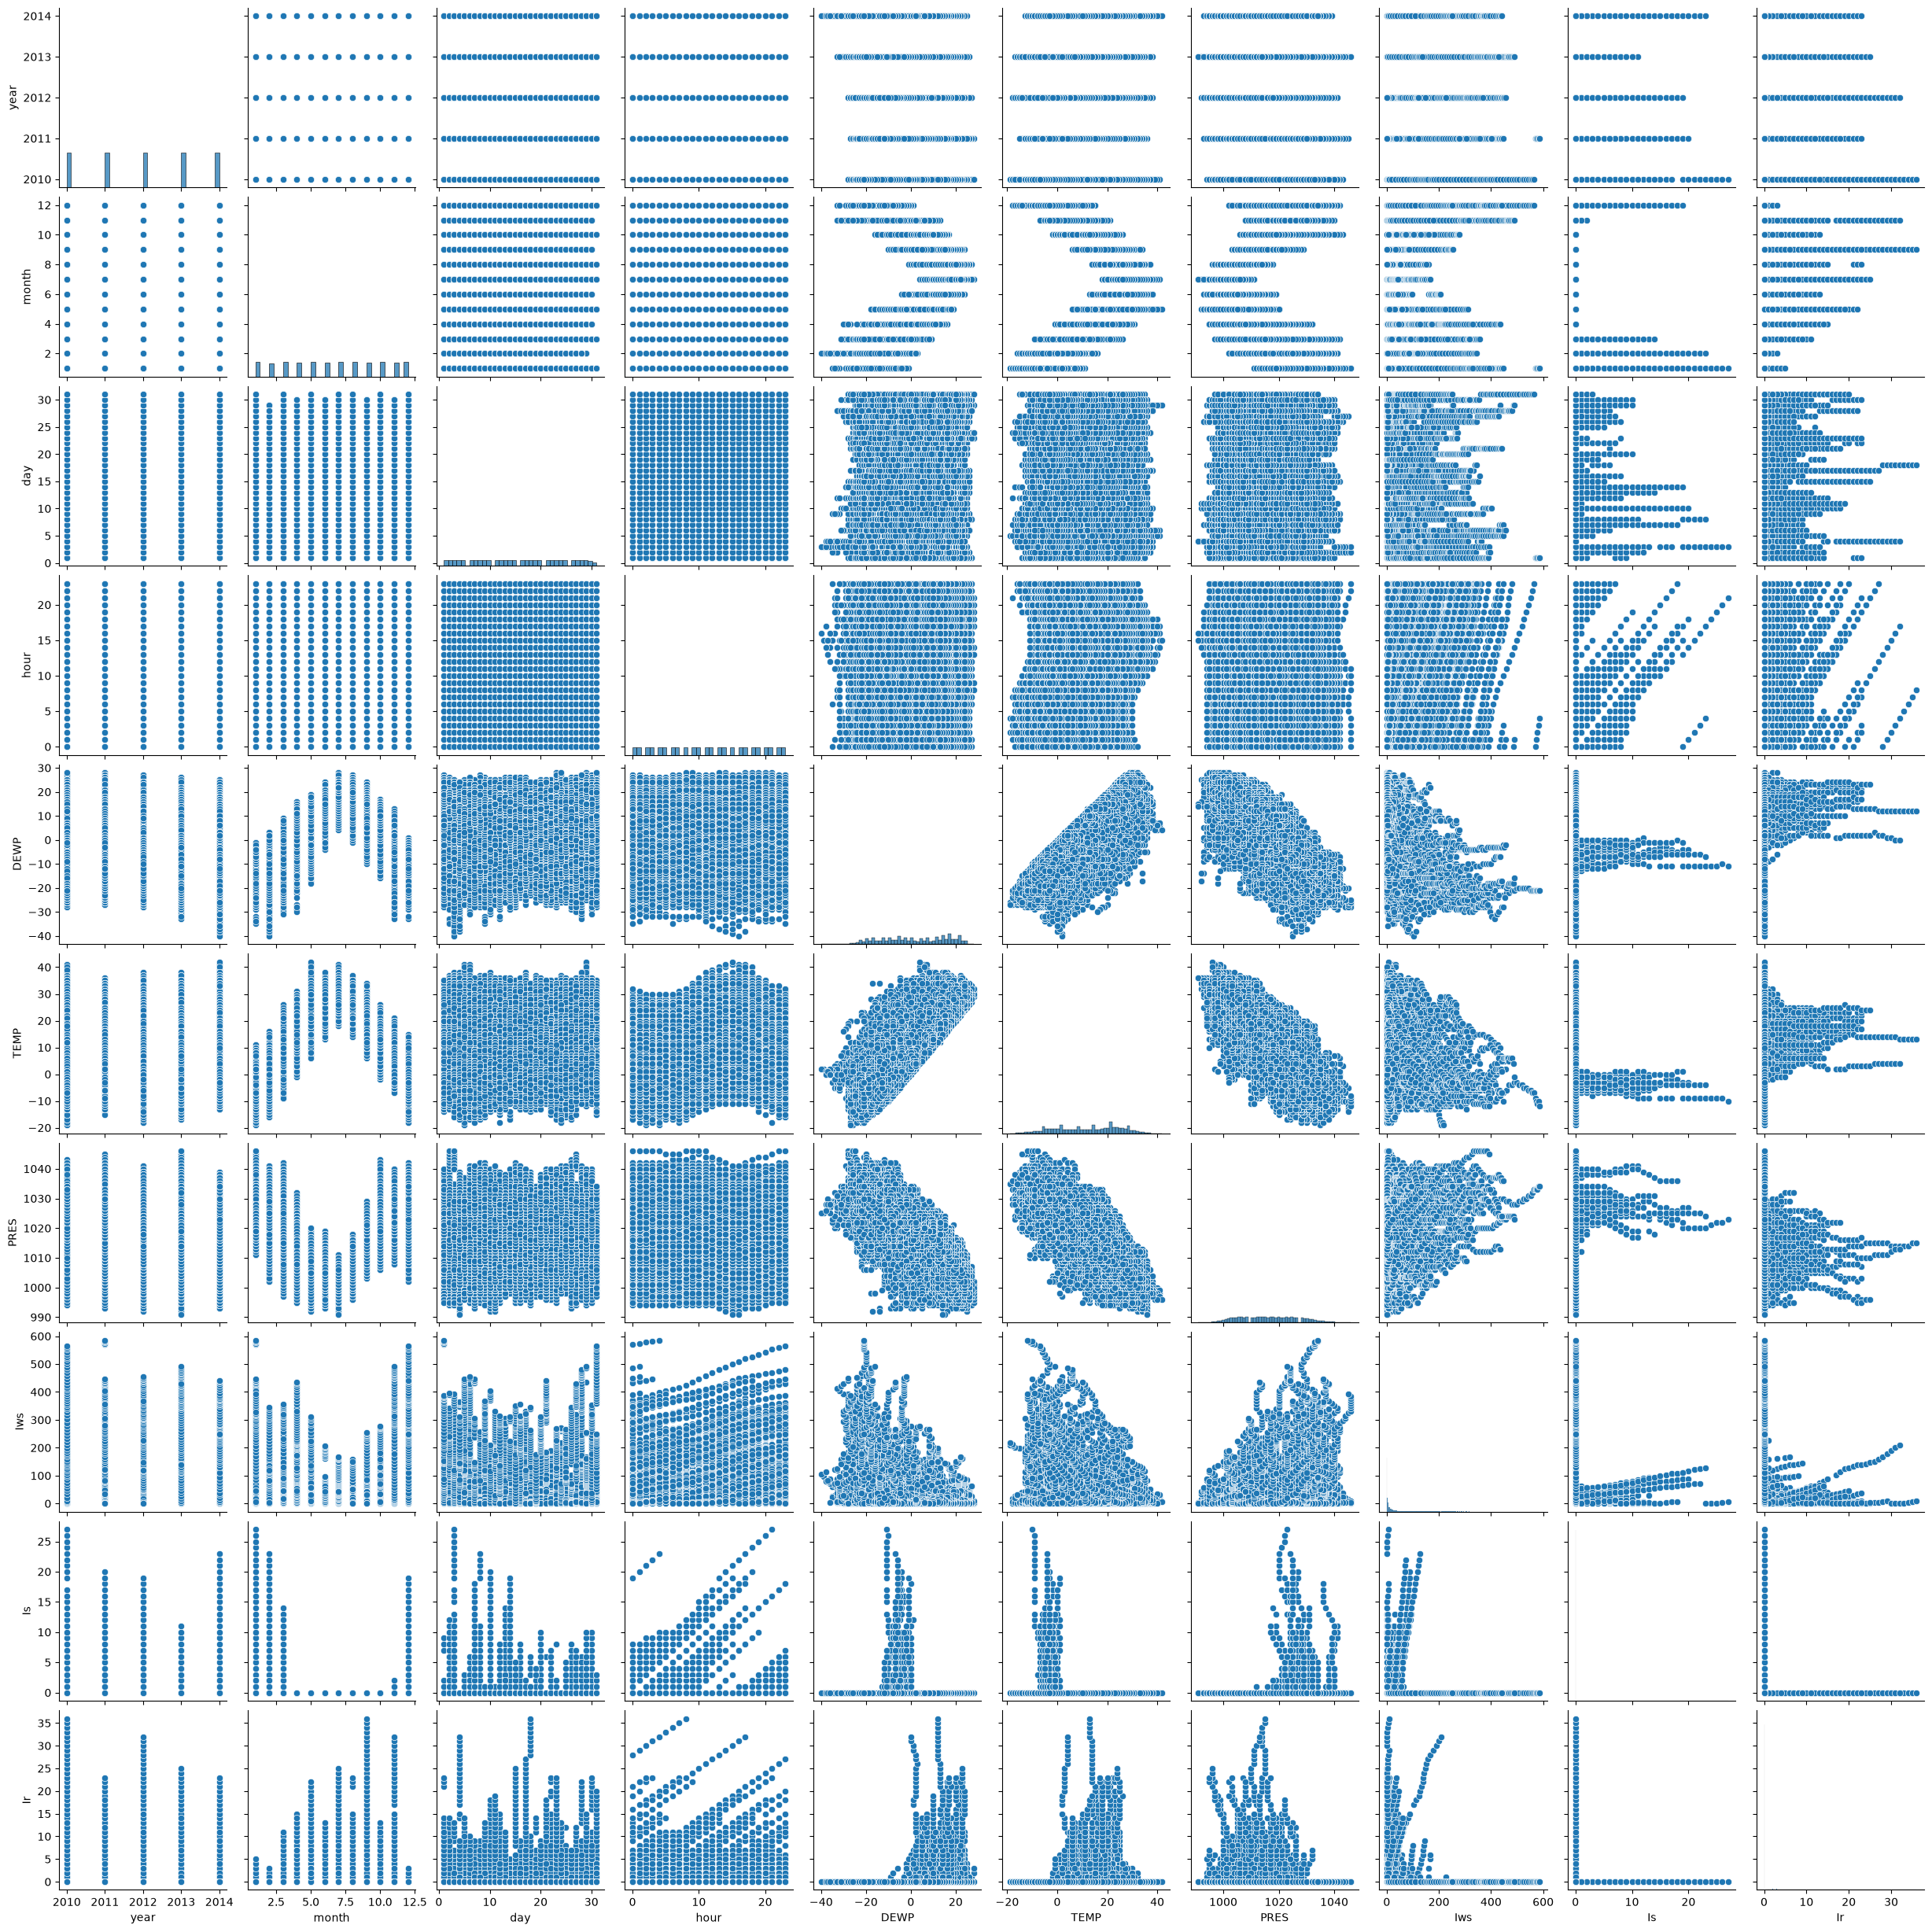

In [123]:
sns.pairplot(X)

## 5.6: Observations about relationships and patterns

# 6: Engineering Domain Knowledge

## 6.1: What do the correlation means in engineering terms? 

The correlations are temperature, dew points and atmospheric pressure. These variables may contain overlapping information about atmospheric conditions.

## 6.2: Are there any unexpected patterns from an engineering perspective?

None.

## 6.3: What physical/process relationships do the data reflect?

The data reflects the atmospheric processes connecting weather conditions to PM2.5 pollution.

## 6.4: Based on your engineering knowledge, are there any missing features that would be important?

The missing important features would be _sources_ of PM2.5 pollution, as most of PM2.5 pollution comes from human activity (such as traffic emission, industrial emissions), and meterological conditions are weaker predictors.

# 7: Challenges Encountered

So far, I have not met any difficulties with data cleaning or outliers.

# 8: Responsible AI Reflection Questions: 

## 8.1: How might poor data quality affect model reliability?

Poor data quality will cause a trained model to learn patterns that do not accurately reflect real-world conditions. 

## 8.2: What ethical or bias issues might exist in this dataset?

The dataset may contain geographical biases because its observations only represent pollution under the conditions present in Beijing in a particular time period. Patterns learned from this dataset therefore may not accurately generalize to other locations or time periods.

In [126]:
y.describe().to_csv("uh.csv")

In [130]:
y.drop("level", axis=1, inplace=True)
y

,pm2.5
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
43819,8.0
43820,10.0
43821,10.0
43822,8.0


In [131]:
y.dtypes.to_csv("t.csv")